In [29]:
# ============================================================
# LOCKED CAUSAL SPECIFICATION
# Define this before calculating any effect estimates.
# ============================================================
PRIMARY_ESTIMAND = "ATE"
PRIMARY_EFFECT_SCALE = "risk_difference"

PRIMARY_PS_MODEL = "xgb"
PRIMARY_OUTCOME_MODEL = "rf"
PRIMARY_COMBINED_ESTIMATOR = "aipw"

PRIMARY_PS_TRUNCATION = None

ALPHA = 0.05
CONFIDENCE_LEVEL = 0.95

print("PRIMARY SPECIFICATION")
print(f"Estimand: {PRIMARY_ESTIMAND}")
print(f"Effect scale: {PRIMARY_EFFECT_SCALE}")
print(f"Propensity model: {PRIMARY_PS_MODEL}")
print(f"Outcome model: {PRIMARY_OUTCOME_MODEL}")
print(f"Combined estimator: {PRIMARY_COMBINED_ESTIMATOR}")
print(f"Propensity truncation: {PRIMARY_PS_TRUNCATION}")

PRIMARY SPECIFICATION
Estimand: ATE
Effect scale: risk_difference
Propensity model: xgb
Outcome model: rf
Combined estimator: aipw
Propensity truncation: None


In [30]:
from pathlib import Path
import numpy as np
import pandas as pd

root_dir = "/Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization"

OUTPUT_DIR = (
    Path(root_dir)
    / "Causal Inference"
    / "model_outputs"
)

ps_predictions = pd.read_csv(
    OUTPUT_DIR / "propensity_oof_predictions.csv"
)

outcome_predictions = pd.read_csv(
    OUTPUT_DIR / "outcome_oof_predictions.csv"
)

analysis = ps_predictions.merge(
    outcome_predictions,
    on=[
        "respondent_id",
        "timely_college",
        "violent_victimization_18_24",
    ],
    how="inner",
    validate="one_to_one",
)

assert len(analysis) == len(ps_predictions)
assert len(analysis) == len(outcome_predictions)
assert analysis["respondent_id"].is_unique

required_primary_columns = [
    f"ps_{PRIMARY_PS_MODEL}_mean",
    f"mu1_{PRIMARY_OUTCOME_MODEL}_mean",
    f"mu0_{PRIMARY_OUTCOME_MODEL}_mean",
]

missing = [
    column
    for column in required_primary_columns
    if column not in analysis.columns
]

assert not missing, f"Missing primary predictions: {missing}"

print(
    f"Loaded and aligned "
    f"{len(analysis):,} respondents."
)

Loaded and aligned 8,467 respondents.


In [31]:
# ============================================================
# EXTRACT AND VALIDATE ANALYSIS VARIABLES
# ============================================================
PS_MODELS = ["logit", "rf", "xgb"]
OUTCOME_MODELS = ["logit", "rf", "xgb"]
SEEDS = [0, 1, 2]

z = analysis["timely_college"].to_numpy(dtype=float)
y = analysis[
    "violent_victimization_18_24"
].to_numpy(dtype=float)

n = len(analysis)

assert set(np.unique(z)) <= {0, 1}
assert set(np.unique(y)) <= {0, 1}
assert np.isfinite(z).all()
assert np.isfinite(y).all()

# Verify every exported propensity score.
for ps_model in PS_MODELS:
    column = f"ps_{ps_model}_mean"
    values = analysis[column].to_numpy()

    assert np.isfinite(values).all()
    assert np.all((values > 0) & (values < 1)), (
        f"{column} contains scores outside (0, 1)"
    )

# Verify every exported outcome probability.
for outcome_model in OUTCOME_MODELS:
    for treatment_level in [0, 1]:
        column = (
            f"mu{treatment_level}_"
            f"{outcome_model}_mean"
        )
        values = analysis[column].to_numpy()

        assert np.isfinite(values).all()
        assert np.all((values >= 0) & (values <= 1)), (
            f"{column} contains probabilities "
            "outside [0, 1]"
        )

print(f"Analysis sample: {n:,}")
print(f"Treated: {int(z.sum()):,}")
print(f"Controls: {int((1 - z).sum()):,}")
print(f"Observed outcome prevalence: {y.mean():.4f}")

raw_treated_risk = y[z == 1].mean()
raw_control_risk = y[z == 0].mean()

print(
    f"Raw treated risk: {raw_treated_risk:.4f}"
)
print(
    f"Raw control risk: {raw_control_risk:.4f}"
)
print(
    "Raw risk difference: "
    f"{100 * (raw_treated_risk - raw_control_risk):.3f} "
    "percentage points"
)

Analysis sample: 8,467
Treated: 3,987
Controls: 4,480
Observed outcome prevalence: 0.0614
Raw treated risk: 0.0584
Raw control risk: 0.0641
Raw risk difference: -0.562 percentage points


In [32]:
# ============================================================
# PROPENSITY-SCORE HANDLING
# ============================================================
def prepare_propensity(
    propensity,
    truncation=None,
):
    """
    Validate or truncate propensity scores.

    truncation=None leaves scores unchanged.
    A value such as 0.01 clips scores to [0.01, 0.99].
    """
    propensity = np.asarray(
        propensity,
        dtype=float,
    )

    if not np.isfinite(propensity).all():
        raise ValueError(
            "Propensity scores contain nonfinite values."
        )

    if truncation is None:
        if np.any(
            (propensity <= 0)
            | (propensity >= 1)
        ):
            raise ValueError(
                "Untruncated propensity scores must "
                "fall strictly between 0 and 1."
            )

        return propensity

    if not 0 < truncation < 0.5:
        raise ValueError(
            "Truncation must be between 0 and 0.5."
        )

    return np.clip(
        propensity,
        truncation,
        1 - truncation,
    )

In [33]:
# ============================================================
# CAUSAL ESTIMATOR FUNCTIONS
# ============================================================
from scipy.stats import t as student_t


def ipw_estimate(
    y,
    z,
    propensity,
    truncation=None,
):
    """
    Normalized/Hajek IPW estimate of the ATE.

    Stabilization constants cancel within the two
    normalized treatment-arm means.
    """
    y = np.asarray(y, dtype=float)
    z = np.asarray(z, dtype=float)

    propensity = prepare_propensity(
        propensity,
        truncation,
    )

    treated_weights = z / propensity
    control_weights = (
        (1 - z) / (1 - propensity)
    )

    risk_treated = np.sum(
        treated_weights * y
    ) / np.sum(treated_weights)

    risk_control = np.sum(
        control_weights * y
    ) / np.sum(control_weights)

    ate = risk_treated - risk_control

    return {
        "risk_treated": risk_treated,
        "risk_control": risk_control,
        "ate": ate,
    }


def gcomp_estimate(mu1, mu0):
    """
    Outcome-model/g-computation estimate.

    mu1: predicted outcome probability if everyone
         were treated.
    mu0: predicted outcome probability if everyone
         were untreated.
    """
    mu1 = np.asarray(mu1, dtype=float)
    mu0 = np.asarray(mu0, dtype=float)

    risk_treated = np.mean(mu1)
    risk_control = np.mean(mu0)
    ate = risk_treated - risk_control

    return {
        "risk_treated": risk_treated,
        "risk_control": risk_control,
        "ate": ate,
    }


def aipw_estimate(
    y,
    z,
    propensity,
    mu1,
    mu0,
    truncation=None,
    alpha=0.05,
):
    """
    Cross-fitted AIPW estimate with an
    influence-function standard error.
    """
    y = np.asarray(y, dtype=float)
    z = np.asarray(z, dtype=float)
    mu1 = np.asarray(mu1, dtype=float)
    mu0 = np.asarray(mu0, dtype=float)

    propensity = prepare_propensity(
        propensity,
        truncation,
    )

    # One-step estimate of E[Y(1)].
    pseudo_treated = (
        mu1
        + z * (y - mu1) / propensity
    )

    # One-step estimate of E[Y(0)].
    pseudo_control = (
        mu0
        + (1 - z)
        * (y - mu0)
        / (1 - propensity)
    )

    # One AIPW treatment-effect contribution
    # per respondent.
    pseudo_effect = (
        pseudo_treated - pseudo_control
    )

    risk_treated = np.mean(pseudo_treated)
    risk_control = np.mean(pseudo_control)
    ate = np.mean(pseudo_effect)

    standard_error = (
        np.std(pseudo_effect, ddof=1)
        / np.sqrt(len(pseudo_effect))
    )

    degrees_freedom = len(pseudo_effect) - 1

    critical_value = student_t.ppf(
        1 - alpha / 2,
        df=degrees_freedom,
    )

    ci_lower = (
        ate - critical_value * standard_error
    )
    ci_upper = (
        ate + critical_value * standard_error
    )

    if standard_error > 0:
        test_statistic = ate / standard_error

        p_value = 2 * student_t.sf(
            abs(test_statistic),
            df=degrees_freedom,
        )
    else:
        test_statistic = np.nan
        p_value = np.nan

    return {
        "risk_treated": risk_treated,
        "risk_control": risk_control,
        "ate": ate,
        "standard_error": standard_error,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "test_statistic": test_statistic,
        "p_value": p_value,
        "pseudo_treated": pseudo_treated,
        "pseudo_control": pseudo_control,
        "pseudo_effect": pseudo_effect,
    }

In [34]:
# ============================================================
# PRIMARY PROPENSITY DIAGNOSTICS
# ============================================================
primary_propensity = prepare_propensity(
    analysis[
        f"ps_{PRIMARY_PS_MODEL}_mean"
    ].to_numpy(),
    PRIMARY_PS_TRUNCATION,
)

treated_prevalence = z.mean()

# Stabilized ATE weights, matching the propensity notebook.
stabilized_weights = np.where(
    z == 1,
    treated_prevalence / primary_propensity,
    (1 - treated_prevalence)
    / (1 - primary_propensity),
)


def effective_sample_size(weights):
    weights = np.asarray(weights, dtype=float)

    return (
        weights.sum() ** 2
        / np.sum(weights ** 2)
    )


treated_weights = stabilized_weights[z == 1]
control_weights = stabilized_weights[z == 0]

primary_ps_diagnostics = pd.Series({
    "minimum propensity": primary_propensity.min(),
    "maximum propensity": primary_propensity.max(),
    "scores below 0.05": (
        primary_propensity < 0.05
    ).sum(),
    "scores above 0.95": (
        primary_propensity > 0.95
    ).sum(),
    "maximum treated weight": treated_weights.max(),
    "maximum control weight": control_weights.max(),
    "treated ESS": effective_sample_size(
        treated_weights
    ),
    "control ESS": effective_sample_size(
        control_weights
    ),
    "treated sample size": len(treated_weights),
    "control sample size": len(control_weights),
})

display(
    primary_ps_diagnostics
    .to_frame("value")
    .round(4)
)

,value
minimum propensity,0.0196
maximum propensity,0.9304
scores below 0.05,74.0000
scores above 0.95,0.0000
maximum treated weight,14.2506
maximum control weight,7.1912
treated ESS,2506.9686
control ESS,3255.3838
treated sample size,3987.0000
control sample size,4480.0000


In [35]:
# ============================================================
# IPW ESTIMATES ACROSS PROPENSITY MODELS
# ============================================================
ipw_rows = []

for ps_model in PS_MODELS:
    propensity = analysis[
        f"ps_{ps_model}_mean"
    ].to_numpy()

    result = ipw_estimate(
        y=y,
        z=z,
        propensity=propensity,
        truncation=PRIMARY_PS_TRUNCATION,
    )

    ipw_rows.append({
        "estimator": "IPW",
        "propensity_model": ps_model,
        "outcome_model": None,
        "risk_treated": result["risk_treated"],
        "risk_control": result["risk_control"],
        "ate": result["ate"],
        "standard_error": np.nan,
        "ci_lower": np.nan,
        "ci_upper": np.nan,
        "p_value": np.nan,
        "primary": False,
    })

ipw_results = pd.DataFrame(ipw_rows)

display(
    ipw_results.assign(
        risk_treated_pct=lambda d:
            100 * d["risk_treated"],
        risk_control_pct=lambda d:
            100 * d["risk_control"],
        ate_percentage_points=lambda d:
            100 * d["ate"],
    )[
        [
            "propensity_model",
            "risk_treated_pct",
            "risk_control_pct",
            "ate_percentage_points",
        ]
    ].round(3)
)

,propensity_model,risk_treated_pct,risk_control_pct,ate_percentage_points
0,logit,5.739,6.198,-0.459
1,rf,5.885,6.262,-0.377
2,xgb,5.757,6.248,-0.491


In [36]:
# ============================================================
# G-COMPUTATION ESTIMATES ACROSS OUTCOME MODELS
# ============================================================
gcomp_rows = []

for outcome_model in OUTCOME_MODELS:
    mu1 = analysis[
        f"mu1_{outcome_model}_mean"
    ].to_numpy()

    mu0 = analysis[
        f"mu0_{outcome_model}_mean"
    ].to_numpy()

    result = gcomp_estimate(
        mu1=mu1,
        mu0=mu0,
    )

    gcomp_rows.append({
        "estimator": "G-computation",
        "propensity_model": None,
        "outcome_model": outcome_model,
        "risk_treated": result["risk_treated"],
        "risk_control": result["risk_control"],
        "ate": result["ate"],
        "standard_error": np.nan,
        "ci_lower": np.nan,
        "ci_upper": np.nan,
        "p_value": np.nan,
        "primary": False,
    })

gcomp_results = pd.DataFrame(gcomp_rows)

display(
    gcomp_results.assign(
        risk_treated_pct=lambda d:
            100 * d["risk_treated"],
        risk_control_pct=lambda d:
            100 * d["risk_control"],
        ate_percentage_points=lambda d:
            100 * d["ate"],
    )[
        [
            "outcome_model",
            "risk_treated_pct",
            "risk_control_pct",
            "ate_percentage_points",
        ]
    ].round(3)
)

,outcome_model,risk_treated_pct,risk_control_pct,ate_percentage_points
0,logit,6.117,6.166,-0.048
1,rf,6.182,6.115,0.066
2,xgb,6.128,6.090,0.039


In [37]:
# ============================================================
# AIPW ESTIMATES FOR EVERY MODEL COMBINATION
# ============================================================
aipw_rows = []
aipw_objects = {}

for ps_model in PS_MODELS:
    propensity = analysis[
        f"ps_{ps_model}_mean"
    ].to_numpy()

    for outcome_model in OUTCOME_MODELS:
        mu1 = analysis[
            f"mu1_{outcome_model}_mean"
        ].to_numpy()

        mu0 = analysis[
            f"mu0_{outcome_model}_mean"
        ].to_numpy()

        result = aipw_estimate(
            y=y,
            z=z,
            propensity=propensity,
            mu1=mu1,
            mu0=mu0,
            truncation=PRIMARY_PS_TRUNCATION,
            alpha=ALPHA,
        )

        is_primary = (
            ps_model == PRIMARY_PS_MODEL
            and outcome_model
            == PRIMARY_OUTCOME_MODEL
        )

        key = (ps_model, outcome_model)
        aipw_objects[key] = result

        aipw_rows.append({
            "estimator": "AIPW",
            "propensity_model": ps_model,
            "outcome_model": outcome_model,
            "risk_treated": result[
                "risk_treated"
            ],
            "risk_control": result[
                "risk_control"
            ],
            "ate": result["ate"],
            "standard_error": result[
                "standard_error"
            ],
            "ci_lower": result["ci_lower"],
            "ci_upper": result["ci_upper"],
            "p_value": result["p_value"],
            "primary": is_primary,
        })

aipw_results = pd.DataFrame(aipw_rows)

aipw_display = aipw_results.assign(
    risk_treated_pct=(
        100 * aipw_results["risk_treated"]
    ),
    risk_control_pct=(
        100 * aipw_results["risk_control"]
    ),
    ate_percentage_points=(
        100 * aipw_results["ate"]
    ),
    ci_lower_pp=(
        100 * aipw_results["ci_lower"]
    ),
    ci_upper_pp=(
        100 * aipw_results["ci_upper"]
    ),
)

display(
    aipw_display[
        [
            "propensity_model",
            "outcome_model",
            "risk_treated_pct",
            "risk_control_pct",
            "ate_percentage_points",
            "ci_lower_pp",
            "ci_upper_pp",
            "p_value",
            "primary",
        ]
    ].round(4)
)

,propensity_model,outcome_model,risk_treated_pct,risk_control_pct,ate_percentage_points,ci_lower_pp,ci_upper_pp,p_value,primary
0,logit,logit,5.2750,6.1391,-0.8641,-2.5690,0.8408,0.3205,False
1,logit,rf,5.6264,6.1946,-0.5682,-2.0913,0.9549,0.4646,False
2,logit,xgb,5.5489,6.1871,-0.6382,-2.1739,0.8975,0.4153,False
3,rf,logit,6.0318,6.1676,-0.1358,-1.1223,0.8507,0.7873,False
4,rf,rf,6.1269,6.1239,0.0030,-0.9800,0.9861,0.9952,False
5,rf,xgb,6.0725,6.1373,-0.0647,-1.0512,0.9217,0.8976,False
6,xgb,logit,5.7735,6.1650,-0.3914,-1.5882,0.8053,0.5214,False
7,xgb,rf,5.8372,6.2060,-0.3688,-1.5635,0.8258,0.5451,True
8,xgb,xgb,5.7906,6.1810,-0.3904,-1.5895,0.8087,0.5234,False


In [38]:
# ============================================================
# PRIMARY AIPW RESULT
# ============================================================
primary_result = aipw_results.loc[
    aipw_results["primary"]
].squeeze()

assert primary_result["propensity_model"] == "xgb"
assert primary_result["outcome_model"] == "rf"

print("PRIMARY ATE RESULT")
print("------------------")
print(
    "Propensity model: "
    f"{primary_result['propensity_model']}"
)
print(
    "Outcome model: "
    f"{primary_result['outcome_model']}"
)
print(
    "Estimated risk under timely enrollment: "
    f"{100 * primary_result['risk_treated']:.3f}%"
)
print(
    "Estimated risk under control: "
    f"{100 * primary_result['risk_control']:.3f}%"
)
print(
    "ATE: "
    f"{100 * primary_result['ate']:.3f} "
    "percentage points"
)
print(
    "95% CI: ["
    f"{100 * primary_result['ci_lower']:.3f}, "
    f"{100 * primary_result['ci_upper']:.3f}"
    "] percentage points"
)
print(
    f"Standard error: "
    f"{100 * primary_result['standard_error']:.3f} "
    "percentage points"
)
print(
    f"Two-sided p-value: "
    f"{primary_result['p_value']:.4f}"
)

PRIMARY ATE RESULT
------------------
Propensity model: xgb
Outcome model: rf
Estimated risk under timely enrollment: 5.837%
Estimated risk under control: 6.206%
ATE: -0.369 percentage points
95% CI: [-1.564, 0.826] percentage points
Standard error: 0.609 percentage points
Two-sided p-value: 0.5451


In [39]:
# ============================================================
# PRIMARY AIPW INFLUENCE-DIAGNOSTIC CHECK
# ============================================================
primary_aipw = aipw_objects[
    (
        PRIMARY_PS_MODEL,
        PRIMARY_OUTCOME_MODEL,
    )
]

primary_pseudo_effect = primary_aipw[
    "pseudo_effect"
]

pseudo_summary = pd.Series(
    primary_pseudo_effect
).describe(
    percentiles=[
        0.001,
        0.01,
        0.05,
        0.5,
        0.95,
        0.99,
        0.999,
    ]
)

display(
    pseudo_summary
    .to_frame("AIPW pseudo-effect")
    .round(4)
)

largest_contributions = (
    analysis[
        [
            "respondent_id",
            "timely_college",
            "violent_victimization_18_24",
        ]
    ]
    .assign(
        propensity=primary_propensity,
        pseudo_effect=primary_pseudo_effect,
        absolute_pseudo_effect=np.abs(
            primary_pseudo_effect
        ),
    )
    .nlargest(
        20,
        "absolute_pseudo_effect",
    )
)

display(
    largest_contributions.round(4)
)

,AIPW pseudo-effect
count,8467.0000
mean,-0.0037
std,0.5608
min,-10.2139
0.1%,-5.3394
1%,-1.7647
5%,-0.3672
50%,0.0502
95%,0.2764
99%,1.7403


,respondent_id,timely_college,violent_victimization_18_24,propensity,pseudo_effect,absolute_pseudo_effect
559,607,1,1,0.0809,11.3035,11.3035
1345,1453,0,1,0.9062,-10.2139,10.2139
4447,4796,1,1,0.0904,10.1533,10.1533
7838,8358,1,1,0.1145,7.7991,7.7991
4482,4833,0,1,0.8758,-7.4920,7.4920
139,150,1,1,0.1267,7.4498,7.4498
6732,7202,1,1,0.1428,6.2625,6.2625
7740,8258,0,1,0.8420,-6.0823,6.0823
2782,3015,0,1,0.8441,-6.0819,6.0819
203,221,0,1,0.8393,-5.9600,5.9600


In [40]:
# ============================================================
# PRIMARY AIPW STABILITY ACROSS CROSS-FITTING SEEDS
# ============================================================
seed_rows = []

for seed in SEEDS:
    propensity = analysis[
        f"ps_{PRIMARY_PS_MODEL}_seed_{seed}"
    ].to_numpy()

    mu1 = analysis[
        f"mu1_{PRIMARY_OUTCOME_MODEL}_seed_{seed}"
    ].to_numpy()

    mu0 = analysis[
        f"mu0_{PRIMARY_OUTCOME_MODEL}_seed_{seed}"
    ].to_numpy()

    result = aipw_estimate(
        y=y,
        z=z,
        propensity=propensity,
        mu1=mu1,
        mu0=mu0,
        truncation=PRIMARY_PS_TRUNCATION,
        alpha=ALPHA,
    )

    seed_rows.append({
        "seed": seed,
        "risk_treated": result[
            "risk_treated"
        ],
        "risk_control": result[
            "risk_control"
        ],
        "ate": result["ate"],
        "standard_error": result[
            "standard_error"
        ],
        "ci_lower": result["ci_lower"],
        "ci_upper": result["ci_upper"],
    })

seed_results = pd.DataFrame(seed_rows)

seed_display = seed_results.assign(
    risk_treated_pct=(
        100 * seed_results["risk_treated"]
    ),
    risk_control_pct=(
        100 * seed_results["risk_control"]
    ),
    ate_pp=100 * seed_results["ate"],
    ci_lower_pp=100 * seed_results["ci_lower"],
    ci_upper_pp=100 * seed_results["ci_upper"],
)

display(
    seed_display[
        [
            "seed",
            "risk_treated_pct",
            "risk_control_pct",
            "ate_pp",
            "ci_lower_pp",
            "ci_upper_pp",
        ]
    ].round(4)
)

print(
    "ATE SD across cross-fitting seeds: "
    f"{100 * seed_results['ate'].std(ddof=1):.4f} "
    "percentage points"
)

,seed,risk_treated_pct,risk_control_pct,ate_pp,ci_lower_pp,ci_upper_pp
0,0,5.7886,6.2221,-0.4335,-1.6479,0.7808
1,1,5.8459,6.2169,-0.3710,-1.5846,0.8426
2,2,5.8506,6.1791,-0.3285,-1.5184,0.8614


ATE SD across cross-fitting seeds: 0.0528 percentage points


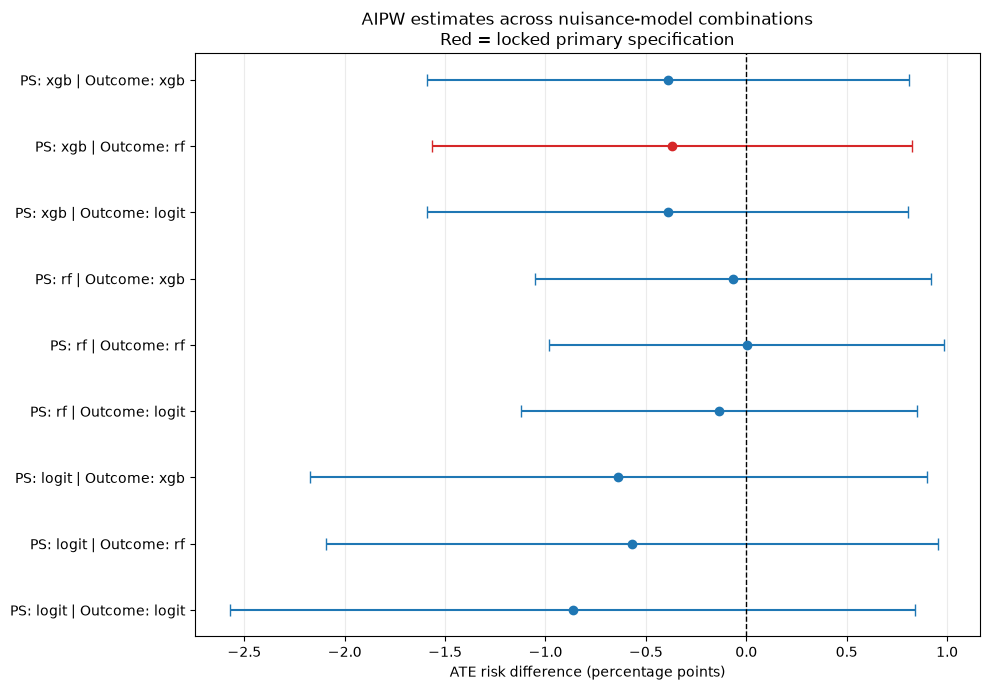

In [41]:
# ============================================================
# AIPW MODEL-COMBINATION SENSITIVITY PLOT
# ============================================================
import matplotlib.pyplot as plt

plot_data = aipw_results.copy()

plot_data["label"] = (
    "PS: "
    + plot_data["propensity_model"]
    + " | Outcome: "
    + plot_data["outcome_model"]
)

plot_data = plot_data.sort_values(
    ["propensity_model", "outcome_model"]
).reset_index(drop=True)

y_positions = np.arange(len(plot_data))

estimate_pp = 100 * plot_data["ate"]
lower_error = 100 * (
    plot_data["ate"] - plot_data["ci_lower"]
)
upper_error = 100 * (
    plot_data["ci_upper"] - plot_data["ate"]
)

colors = np.where(
    plot_data["primary"],
    "tab:red",
    "tab:blue",
)

fig, ax = plt.subplots(figsize=(10, 7))

for index in range(len(plot_data)):
    ax.errorbar(
        estimate_pp.iloc[index],
        y_positions[index],
        xerr=np.array([
            [lower_error.iloc[index]],
            [upper_error.iloc[index]],
        ]),
        fmt="o",
        color=colors[index],
        capsize=4,
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["label"])
ax.set_xlabel("ATE risk difference (percentage points)")
ax.set_title(
    "AIPW estimates across nuisance-model combinations\n"
    "Red = locked primary specification"
)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# COMBINE ALL ESTIMATOR RESULTS
# ============================================================
all_results = pd.concat(
    [
        ipw_results,
        gcomp_results,
        aipw_results,
    ],
    ignore_index=True,
)

all_results["risk_treated_pct"] = (
    100 * all_results["risk_treated"]
)
all_results["risk_control_pct"] = (
    100 * all_results["risk_control"]
)
all_results["ate_percentage_points"] = (
    100 * all_results["ate"]
)
all_results["ci_lower_pp"] = (
    100 * all_results["ci_lower"]
)
all_results["ci_upper_pp"] = (
    100 * all_results["ci_upper"]
)

display_columns = [
    "estimator",
    "propensity_model",
    "outcome_model",
    "risk_treated_pct",
    "risk_control_pct",
    "ate_percentage_points",
    "ci_lower_pp",
    "ci_upper_pp",
    "p_value",
    "primary",
]

display(
    all_results[display_columns]
    .round(4)
)

,estimator,propensity_model,outcome_model,risk_treated_pct,risk_control_pct,ate_percentage_points,ci_lower_pp,ci_upper_pp,p_value,primary
0,IPW,logit,None,5.7391,6.1978,-0.4587,NaN,NaN,NaN,False
1,IPW,rf,None,5.8851,6.2620,-0.3770,NaN,NaN,NaN,False
2,IPW,xgb,None,5.7568,6.2478,-0.4910,NaN,NaN,NaN,False
3,G-computation,None,logit,6.1171,6.1656,-0.0484,NaN,NaN,NaN,False
4,G-computation,None,rf,6.1815,6.1152,0.0663,NaN,NaN,NaN,False
5,G-computation,None,xgb,6.1283,6.0898,0.0386,NaN,NaN,NaN,False
6,AIPW,logit,logit,5.2750,6.1391,-0.8641,-2.5690,0.8408,0.3205,False
7,AIPW,logit,rf,5.6264,6.1946,-0.5682,-2.0913,0.9549,0.4646,False
8,AIPW,logit,xgb,5.5489,6.1871,-0.6382,-2.1739,0.8975,0.4153,False
9,AIPW,rf,logit,6.0318,6.1676,-0.1358,-1.1223,0.8507,0.7873,False


In [43]:
# ============================================================
# EXPORT ATE RESULTS
# ============================================================
import json

results_path = (
    OUTPUT_DIR
    / "ate_model_comparison.csv"
)

all_results.to_csv(
    results_path,
    index=False,
)

primary_summary = {
    "estimand": PRIMARY_ESTIMAND,
    "effect_scale": PRIMARY_EFFECT_SCALE,
    "estimator": PRIMARY_COMBINED_ESTIMATOR,
    "propensity_model": PRIMARY_PS_MODEL,
    "outcome_model": PRIMARY_OUTCOME_MODEL,
    "propensity_truncation": PRIMARY_PS_TRUNCATION,
    "analysis_sample_n": int(n),
    "risk_treated": float(
        primary_result["risk_treated"]
    ),
    "risk_control": float(
        primary_result["risk_control"]
    ),
    "ate": float(primary_result["ate"]),
    "standard_error": float(
        primary_result["standard_error"]
    ),
    "ci_lower": float(
        primary_result["ci_lower"]
    ),
    "ci_upper": float(
        primary_result["ci_upper"]
    ),
    "p_value": float(
        primary_result["p_value"]
    ),
}

primary_path = (
    OUTPUT_DIR
    / "primary_ate_result.json"
)

with open(
    primary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        primary_summary,
        file,
        indent=2,
        sort_keys=True,
    )

print(f"Saved all estimates to: {results_path}")
print(f"Saved primary result to: {primary_path}")

Saved all estimates to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/ate_model_comparison.csv
Saved primary result to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/primary_ate_result.json


# Propensity Truncation Sensitivity Analysis

In [44]:
# ============================================================
# PROPENSITY-TRUNCATION SENSITIVITY ANALYSIS
# ============================================================
TRUNCATION_LEVELS = [
    None,   # Locked primary specification
    0.025,
    0.05,
    0.10,   # Aggressive stress test
]

raw_propensity = analysis[
    f"ps_{PRIMARY_PS_MODEL}_mean"
].to_numpy()

primary_mu1 = analysis[
    f"mu1_{PRIMARY_OUTCOME_MODEL}_mean"
].to_numpy()

primary_mu0 = analysis[
    f"mu0_{PRIMARY_OUTCOME_MODEL}_mean"
].to_numpy()


def effective_sample_size(weights):
    weights = np.asarray(weights, dtype=float)

    return (
        weights.sum() ** 2
        / np.sum(weights ** 2)
    )


truncation_rows = []
truncation_objects = {}

for truncation in TRUNCATION_LEVELS:
    adjusted_propensity = prepare_propensity(
        raw_propensity,
        truncation=truncation,
    )

    result = aipw_estimate(
        y=y,
        z=z,
        propensity=raw_propensity,
        mu1=primary_mu1,
        mu0=primary_mu0,
        truncation=truncation,
        alpha=ALPHA,
    )

    treatment_prevalence = z.mean()

    stabilized_weights = np.where(
        z == 1,
        treatment_prevalence
        / adjusted_propensity,
        (1 - treatment_prevalence)
        / (1 - adjusted_propensity),
    )

    treated_weights = stabilized_weights[z == 1]
    control_weights = stabilized_weights[z == 0]

    if truncation is None:
        n_clipped_low = 0
        n_clipped_high = 0
        label = "None (primary)"
    else:
        n_clipped_low = int(
            (raw_propensity < truncation).sum()
        )
        n_clipped_high = int(
            (
                raw_propensity
                > (1 - truncation)
            ).sum()
        )
        label = (
            f"{truncation:.3f}–"
            f"{1 - truncation:.3f}"
        )

    n_clipped_total = (
        n_clipped_low + n_clipped_high
    )

    pseudo_effect = result["pseudo_effect"]

    truncation_objects[truncation] = result

    truncation_rows.append({
        "truncation": truncation,
        "label": label,
        "primary": truncation is None,
        "n_clipped_low": n_clipped_low,
        "n_clipped_high": n_clipped_high,
        "n_clipped_total": n_clipped_total,
        "percent_clipped": (
            100 * n_clipped_total / n
        ),
        "minimum_adjusted_ps": (
            adjusted_propensity.min()
        ),
        "maximum_adjusted_ps": (
            adjusted_propensity.max()
        ),
        "risk_treated": result[
            "risk_treated"
        ],
        "risk_control": result[
            "risk_control"
        ],
        "ate": result["ate"],
        "standard_error": result[
            "standard_error"
        ],
        "ci_lower": result["ci_lower"],
        "ci_upper": result["ci_upper"],
        "p_value": result["p_value"],
        "treated_max_weight": (
            treated_weights.max()
        ),
        "control_max_weight": (
            control_weights.max()
        ),
        "treated_ess": effective_sample_size(
            treated_weights
        ),
        "control_ess": effective_sample_size(
            control_weights
        ),
        "pseudo_effect_sd": np.std(
            pseudo_effect,
            ddof=1,
        ),
        "maximum_absolute_pseudo_effect": (
            np.abs(pseudo_effect).max()
        ),
    })

truncation_results = pd.DataFrame(
    truncation_rows
)

truncation_results[
    "risk_treated_pct"
] = 100 * truncation_results["risk_treated"]

truncation_results[
    "risk_control_pct"
] = 100 * truncation_results["risk_control"]

truncation_results[
    "ate_pp"
] = 100 * truncation_results["ate"]

truncation_results[
    "standard_error_pp"
] = 100 * truncation_results["standard_error"]

truncation_results[
    "ci_lower_pp"
] = 100 * truncation_results["ci_lower"]

truncation_results[
    "ci_upper_pp"
] = 100 * truncation_results["ci_upper"]

In [45]:
# ============================================================
# DISPLAY TRUNCATION SENSITIVITY RESULTS
# ============================================================
display_columns = [
    "label",
    "n_clipped_total",
    "percent_clipped",
    "risk_treated_pct",
    "risk_control_pct",
    "ate_pp",
    "standard_error_pp",
    "ci_lower_pp",
    "ci_upper_pp",
    "p_value",
    "treated_max_weight",
    "control_max_weight",
    "treated_ess",
    "control_ess",
    "pseudo_effect_sd",
    "maximum_absolute_pseudo_effect",
    "primary",
]

display(
    truncation_results[
        display_columns
    ].round(4)
)

,label,n_clipped_total,percent_clipped,risk_treated_pct,risk_control_pct,ate_pp,standard_error_pp,ci_lower_pp,ci_upper_pp,p_value,treated_max_weight,control_max_weight,treated_ess,control_ess,pseudo_effect_sd,maximum_absolute_pseudo_effect,primary
0,None (primary),0,0.0000,5.8372,6.2060,-0.3688,0.6095,-1.5635,0.8258,0.5451,14.2506,7.1912,2506.9686,3255.3838,0.5608,11.3035,True
1,0.025–0.975,3,0.0354,5.8372,6.2060,-0.3688,0.6095,-1.5635,0.8258,0.5451,14.2506,7.1912,2506.9686,3255.3870,0.5608,11.3035,False
2,0.050–0.950,74,0.8740,5.8519,6.2059,-0.3540,0.6088,-1.5473,0.8394,0.5610,9.4177,7.1912,2560.1091,3255.7807,0.5602,11.3035,False
3,0.100–0.900,540,6.3777,5.9158,6.2060,-0.2902,0.5981,-1.4627,0.8823,0.6275,4.7089,5.2911,2804.0407,3278.4811,0.5504,9.5825,False


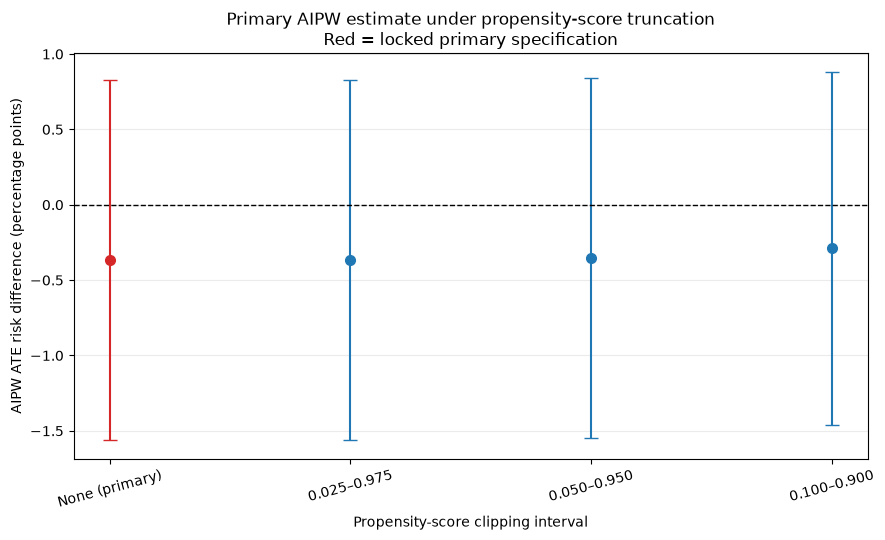

In [46]:
# ============================================================
# TRUNCATION SENSITIVITY PLOT
# ============================================================
import matplotlib.pyplot as plt

plot_data = truncation_results.copy()

positions = np.arange(len(plot_data))

estimate = plot_data["ate_pp"]
lower_error = (
    estimate - plot_data["ci_lower_pp"]
)
upper_error = (
    plot_data["ci_upper_pp"] - estimate
)

colors = np.where(
    plot_data["primary"],
    "tab:red",
    "tab:blue",
)

fig, ax = plt.subplots(figsize=(9, 5.5))

for index in range(len(plot_data)):
    ax.errorbar(
        positions[index],
        estimate.iloc[index],
        yerr=np.array([
            [lower_error.iloc[index]],
            [upper_error.iloc[index]],
        ]),
        fmt="o",
        color=colors[index],
        capsize=5,
        markersize=7,
    )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_xticks(positions)
ax.set_xticklabels(
    plot_data["label"],
    rotation=15,
)

ax.set_ylabel(
    "AIPW ATE risk difference "
    "(percentage points)"
)

ax.set_xlabel(
    "Propensity-score clipping interval"
)

ax.set_title(
    "Primary AIPW estimate under "
    "propensity-score truncation\n"
    "Red = locked primary specification"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [47]:
# ============================================================
# PSEUDO-EFFECT TAILS UNDER TRUNCATION
# ============================================================
tail_rows = []

for truncation in TRUNCATION_LEVELS:
    pseudo_effect = truncation_objects[
        truncation
    ]["pseudo_effect"]

    label = truncation_results.loc[
        truncation_results["truncation"].isna()
        if truncation is None
        else (
            truncation_results["truncation"]
            == truncation
        ),
        "label",
    ].iloc[0]

    tail_rows.append({
        "label": label,
        "minimum": pseudo_effect.min(),
        "p001": np.quantile(
            pseudo_effect,
            0.001,
        ),
        "p01": np.quantile(
            pseudo_effect,
            0.01,
        ),
        "median": np.median(
            pseudo_effect
        ),
        "p99": np.quantile(
            pseudo_effect,
            0.99,
        ),
        "p999": np.quantile(
            pseudo_effect,
            0.999,
        ),
        "maximum": pseudo_effect.max(),
        "number_abs_above_2": int(
            (np.abs(pseudo_effect) > 2).sum()
        ),
        "number_abs_above_5": int(
            (np.abs(pseudo_effect) > 5).sum()
        ),
        "number_abs_above_10": int(
            (np.abs(pseudo_effect) > 10).sum()
        ),
    })

pseudo_tail_results = pd.DataFrame(
    tail_rows
)

display(
    pseudo_tail_results.round(4)
)

,label,minimum,p001,p01,median,p99,p999,maximum,number_abs_above_2,number_abs_above_5,number_abs_above_10
0,None (primary),-10.2139,-5.3394,-1.7647,0.0502,1.7403,4.54,11.3035,120,16,3
1,0.025–0.975,-10.2139,-5.3394,-1.7647,0.0502,1.7403,4.54,11.3035,120,16,3
2,0.050–0.950,-10.2139,-5.3394,-1.7647,0.0503,1.7403,4.54,11.3035,120,16,3
3,0.100–0.900,-9.5825,-5.3394,-1.7455,0.0504,1.7403,4.54,9.1774,118,16,0


In [48]:
# ============================================================
# EXPORT TRUNCATION SENSITIVITY RESULTS
# ============================================================
truncation_path = (
    OUTPUT_DIR
    / "aipw_truncation_sensitivity.csv"
)

truncation_results.to_csv(
    truncation_path,
    index=False,
)

pseudo_tail_path = (
    OUTPUT_DIR
    / "aipw_truncation_pseudo_tails.csv"
)

pseudo_tail_results.to_csv(
    pseudo_tail_path,
    index=False,
)

print(
    "Saved truncation estimates to: "
    f"{truncation_path}"
)

print(
    "Saved pseudo-effect diagnostics to: "
    f"{pseudo_tail_path}"
)

Saved truncation estimates to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/aipw_truncation_sensitivity.csv
Saved pseudo-effect diagnostics to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/aipw_truncation_pseudo_tails.csv


# Bootstrap for IPW and Outcome Modeling

In [49]:
# ============================================================
# PREPARE DATA FOR FULL-REFIT BOOTSTRAP
# ============================================================
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

ID_COL = "respondent_id"
TREATMENT = "timely_college"
OUTCOME = "violent_victimization_18_24"

numeric_features = [
    "total_number_of_incarcerations",
    "days_r_absent_from_school",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "household_net_worth",
    "household_size",
    "asvab_math_verbal_score_percent",
]

categorical_features = [
    "teachers_good",
    "discipline_is_fair_agree_disagree",
    "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month",
    "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex",
    "bullying_victim_before_age_12",
    "r_victim_of_bullying_12_18_years",
    "earliest_arrest_before_18",
    "sex",
    "r_ever_live_through_hard_times",
    "biological_father_education",
    "biological_mother_education",
    "race_ethnicity",
    "mother_serve_prison_sentence",
    "father_serve_prison_sentence",
]

model_features = (
    numeric_features + categorical_features
)

bootstrap_source = pd.read_csv(
    Path(root_dir)
    / "Data and Resources"
    / "final_data.csv"
)

# Apply the same negative-code cleaning used by the
# nuisance-model notebooks.
numeric_columns = (
    bootstrap_source
    .select_dtypes(include="number")
    .columns
    .difference([ID_COL])
)

bootstrap_source[numeric_columns] = (
    bootstrap_source[numeric_columns]
    .mask(
        bootstrap_source[numeric_columns] < 0
    )
)

bootstrap_source = bootstrap_source.loc[
    bootstrap_source[TREATMENT].notna()
    & bootstrap_source[OUTCOME].notna(),
    [
        ID_COL,
        TREATMENT,
        OUTCOME,
    ] + model_features,
].copy()

# Match the exact order of the primary ATE sample.
bootstrap_source = (
    bootstrap_source
    .set_index(ID_COL)
    .loc[analysis[ID_COL].astype(int)]
    .reset_index()
)

assert len(bootstrap_source) == len(analysis)
assert bootstrap_source[ID_COL].is_unique

assert np.array_equal(
    bootstrap_source[ID_COL].to_numpy(),
    analysis[ID_COL].to_numpy(),
)

assert np.array_equal(
    bootstrap_source[TREATMENT].to_numpy(),
    z,
)

assert np.array_equal(
    bootstrap_source[OUTCOME].to_numpy(),
    y,
)

X_bootstrap_base = (
    bootstrap_source[model_features]
    .reset_index(drop=True)
)

z_bootstrap_base = (
    bootstrap_source[TREATMENT]
    .astype(int)
    .reset_index(drop=True)
)

y_bootstrap_base = (
    bootstrap_source[OUTCOME]
    .astype(int)
    .reset_index(drop=True)
)

id_bootstrap_base = (
    bootstrap_source[ID_COL]
    .astype(int)
    .reset_index(drop=True)
)

print(
    "Bootstrap source prepared: "
    f"{len(bootstrap_source):,} respondents."
)

Bootstrap source prepared: 8,467 respondents.


In [50]:
# ============================================================
# LOCKED PRIMARY BOOTSTRAP MODEL DEFINITIONS
# ============================================================
BOOTSTRAP_N_SPLITS = 5

PRIMARY_PS_PARAMS = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 5.0,
}

PRIMARY_OUTCOME_PARAMS = {
    "n_estimators": 500,
    "max_depth": 5,
    "min_samples_leaf": 30,
    "max_features": 0.5,
}


def make_bootstrap_preprocessor(
    include_treatment,
):
    parts = [
        (
            "num",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    ),
                ),
            ]),
            numeric_features,
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    ),
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                    ),
                ),
            ]),
            categorical_features,
        ),
    ]

    if include_treatment:
        parts.append(
            (
                "trt",
                "passthrough",
                [TREATMENT],
            )
        )

    return ColumnTransformer(parts)


def make_primary_ps_model(seed):
    return Pipeline([
        (
            "prep",
            make_bootstrap_preprocessor(
                include_treatment=False
            ),
        ),
        (
            "clf",
            XGBClassifier(
                **PRIMARY_PS_PARAMS,
                eval_metric="logloss",
                n_jobs=-1,
                random_state=seed,
            ),
        ),
    ])


def make_primary_outcome_model(seed):
    return Pipeline([
        (
            "prep",
            make_bootstrap_preprocessor(
                include_treatment=True
            ),
        ),
        (
            "clf",
            RandomForestClassifier(
                **PRIMARY_OUTCOME_PARAMS,
                n_jobs=-1,
                random_state=seed,
            ),
        ),
    ])

In [51]:
# ============================================================
# ONE FULL-REFIT BOOTSTRAP REPLICATE
# ============================================================
def run_bootstrap_replicate(
    replicate_seed,
):
    """
    1. Resample respondents with replacement.
    2. Keep repeated copies of a respondent in the
       same cross-fitting fold.
    3. Refit XGBoost propensity models.
    4. Refit RF outcome models.
    5. Calculate primary IPW and g-computation ATEs.
    """
    rng = np.random.default_rng(
        replicate_seed
    )

    sample_indices = rng.integers(
        low=0,
        high=len(X_bootstrap_base),
        size=len(X_bootstrap_base),
    )

    X_b = (
        X_bootstrap_base
        .iloc[sample_indices]
        .reset_index(drop=True)
    )

    z_b = (
        z_bootstrap_base
        .iloc[sample_indices]
        .reset_index(drop=True)
    )

    y_b = (
        y_bootstrap_base
        .iloc[sample_indices]
        .reset_index(drop=True)
    )

    respondent_groups = (
        id_bootstrap_base
        .iloc[sample_indices]
        .reset_index(drop=True)
    )

    XZ_b = X_b.assign(
        **{TREATMENT: z_b}
    )

    n_b = len(X_b)

    propensity_oof = np.zeros(n_b)
    mu1_oof = np.zeros(n_b)
    mu0_oof = np.zeros(n_b)
    received_prediction = np.zeros(
        n_b,
        dtype=bool,
    )

    # Grouped folds prevent duplicate bootstrap copies
    # of the same respondent from appearing in both the
    # training and test portions of a fold.
    splitter = StratifiedGroupKFold(
        n_splits=BOOTSTRAP_N_SPLITS,
        shuffle=True,
        random_state=replicate_seed,
    )

    for train_idx, test_idx in splitter.split(
        X_b,
        z_b,
        groups=respondent_groups,
    ):
        ps_model = make_primary_ps_model(
            replicate_seed
        )

        ps_model.fit(
            X_b.iloc[train_idx],
            z_b.iloc[train_idx],
        )

        propensity_oof[test_idx] = (
            ps_model.predict_proba(
                X_b.iloc[test_idx]
            )[:, 1]
        )

        outcome_model = (
            make_primary_outcome_model(
                replicate_seed
            )
        )

        outcome_model.fit(
            XZ_b.iloc[train_idx],
            y_b.iloc[train_idx],
        )

        XZ_test = XZ_b.iloc[test_idx]

        mu1_oof[test_idx] = (
            outcome_model.predict_proba(
                XZ_test.assign(
                    **{TREATMENT: 1}
                )
            )[:, 1]
        )

        mu0_oof[test_idx] = (
            outcome_model.predict_proba(
                XZ_test.assign(
                    **{TREATMENT: 0}
                )
            )[:, 1]
        )

        received_prediction[test_idx] = True

    assert received_prediction.all()
    assert np.isfinite(propensity_oof).all()
    assert np.isfinite(mu1_oof).all()
    assert np.isfinite(mu0_oof).all()

    assert np.all(
        (propensity_oof > 0)
        & (propensity_oof < 1)
    )

    ipw_result = ipw_estimate(
        y=y_b.to_numpy(),
        z=z_b.to_numpy(),
        propensity=propensity_oof,
        truncation=PRIMARY_PS_TRUNCATION,
    )

    gcomp_result = gcomp_estimate(
        mu1=mu1_oof,
        mu0=mu0_oof,
    )

    return {
        "replicate_seed": replicate_seed,
        "ipw_ate": ipw_result["ate"],
        "ipw_risk_treated": (
            ipw_result["risk_treated"]
        ),
        "ipw_risk_control": (
            ipw_result["risk_control"]
        ),
        "gcomp_ate": gcomp_result["ate"],
        "gcomp_risk_treated": (
            gcomp_result["risk_treated"]
        ),
        "gcomp_risk_control": (
            gcomp_result["risk_control"]
        ),
        "minimum_propensity": (
            propensity_oof.min()
        ),
        "maximum_propensity": (
            propensity_oof.max()
        ),
        "n_unique_respondents": (
            respondent_groups.nunique()
        ),
    }

In [52]:
# ============================================================
# RUN FULL-REFIT BOOTSTRAP
# ============================================================
import time

# Start with 100. Change to 500 after confirming
# that the complete workflow runs correctly.
N_BOOTSTRAP = 500
BOOTSTRAP_RANDOM_SEED = 20261101

checkpoint_path = (
    OUTPUT_DIR
    / "primary_ipw_gcomp_bootstrap_checkpoint.csv"
)

master_rng = np.random.default_rng(
    BOOTSTRAP_RANDOM_SEED
)

replicate_seeds = master_rng.integers(
    low=1,
    high=np.iinfo(np.int32).max,
    size=N_BOOTSTRAP,
)

bootstrap_rows = []
start_time = time.time()

for replicate_number, replicate_seed in enumerate(
    replicate_seeds,
    start=1,
):
    result = run_bootstrap_replicate(
        int(replicate_seed)
    )

    result["replicate"] = replicate_number
    bootstrap_rows.append(result)

    if (
        replicate_number % 10 == 0
        or replicate_number == N_BOOTSTRAP
    ):
        elapsed_minutes = (
            time.time() - start_time
        ) / 60

        bootstrap_results = pd.DataFrame(
            bootstrap_rows
        )

        # Checkpoint protects against losing completed
        # replicates during a long run.
        bootstrap_results.to_csv(
            checkpoint_path,
            index=False,
        )

        print(
            f"Completed {replicate_number}/"
            f"{N_BOOTSTRAP} replicates "
            f"in {elapsed_minutes:.1f} minutes."
        )

bootstrap_results = pd.DataFrame(
    bootstrap_rows
)

print("Bootstrap completed.")

Completed 10/500 replicates in 0.9 minutes.
Completed 20/500 replicates in 1.7 minutes.
Completed 30/500 replicates in 2.7 minutes.
Completed 40/500 replicates in 3.5 minutes.
Completed 50/500 replicates in 4.4 minutes.
Completed 60/500 replicates in 5.3 minutes.
Completed 70/500 replicates in 6.2 minutes.
Completed 80/500 replicates in 7.0 minutes.
Completed 90/500 replicates in 7.9 minutes.
Completed 100/500 replicates in 8.8 minutes.
Completed 110/500 replicates in 9.7 minutes.
Completed 120/500 replicates in 10.6 minutes.
Completed 130/500 replicates in 11.5 minutes.
Completed 140/500 replicates in 12.4 minutes.
Completed 150/500 replicates in 13.3 minutes.
Completed 160/500 replicates in 14.3 minutes.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Completed 170/500 replicates in 15.2 minutes.
Completed 180/500 replicates in 16.1 minutes.
Completed 190/500 replicates in 17.0 minutes.
Completed 200/500 replicates in 17.9 minutes.
Completed 210/500 replicates in 18.8 minutes.
Completed 220/500 replicates in 19.6 minutes.
Completed 230/500 replicates in 20.6 minutes.
Completed 240/500 replicates in 21.4 minutes.
Completed 250/500 replicates in 22.3 minutes.
Completed 260/500 replicates in 23.2 minutes.
Completed 270/500 replicates in 24.1 minutes.
Completed 280/500 replicates in 25.0 minutes.
Completed 290/500 replicates in 25.9 minutes.
Completed 300/500 replicates in 26.9 minutes.
Completed 310/500 replicates in 27.8 minutes.
Completed 320/500 replicates in 28.7 minutes.
Completed 330/500 replicates in 29.5 minutes.
Completed 340/500 replicates in 30.4 minutes.
Completed 350/500 replicates in 31.4 minutes.
Completed 360/500 replicates in 32.6 minutes.
Completed 370/500 replicates in 33.7 minutes.
Completed 380/500 replicates in 34

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Completed 500/500 replicates in 48.2 minutes.
Bootstrap completed.


In [53]:
# ============================================================
# BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================
primary_ipw_point = (
    ipw_results.loc[
        ipw_results["propensity_model"]
        == PRIMARY_PS_MODEL,
        "ate",
    ]
    .iloc[0]
)

primary_gcomp_point = (
    gcomp_results.loc[
        gcomp_results["outcome_model"]
        == PRIMARY_OUTCOME_MODEL,
        "ate",
    ]
    .iloc[0]
)


def summarize_bootstrap(
    bootstrap_estimates,
    original_estimate,
    estimator_name,
):
    bootstrap_estimates = np.asarray(
        bootstrap_estimates,
        dtype=float,
    )

    lower = np.quantile(
        bootstrap_estimates,
        ALPHA / 2,
    )

    upper = np.quantile(
        bootstrap_estimates,
        1 - ALPHA / 2,
    )

    bootstrap_standard_error = np.std(
        bootstrap_estimates,
        ddof=1,
    )

    bootstrap_bias = (
        np.mean(bootstrap_estimates)
        - original_estimate
    )

    return {
        "estimator": estimator_name,
        "original_ate": original_estimate,
        "bootstrap_mean": (
            np.mean(bootstrap_estimates)
        ),
        "bootstrap_bias": bootstrap_bias,
        "bootstrap_standard_error": (
            bootstrap_standard_error
        ),
        "ci_lower": lower,
        "ci_upper": upper,
        "n_bootstrap": len(
            bootstrap_estimates
        ),
    }


ipw_bootstrap_summary = summarize_bootstrap(
    bootstrap_estimates=(
        bootstrap_results["ipw_ate"]
    ),
    original_estimate=primary_ipw_point,
    estimator_name="IPW: XGBoost propensity",
)

gcomp_bootstrap_summary = summarize_bootstrap(
    bootstrap_estimates=(
        bootstrap_results["gcomp_ate"]
    ),
    original_estimate=primary_gcomp_point,
    estimator_name="G-computation: RF outcome",
)

bootstrap_summary = pd.DataFrame([
    ipw_bootstrap_summary,
    gcomp_bootstrap_summary,
])

bootstrap_summary[
    "original_ate_pp"
] = 100 * bootstrap_summary["original_ate"]

bootstrap_summary[
    "bootstrap_mean_pp"
] = 100 * bootstrap_summary["bootstrap_mean"]

bootstrap_summary[
    "bootstrap_bias_pp"
] = 100 * bootstrap_summary["bootstrap_bias"]

bootstrap_summary[
    "bootstrap_standard_error_pp"
] = (
    100
    * bootstrap_summary[
        "bootstrap_standard_error"
    ]
)

bootstrap_summary[
    "ci_lower_pp"
] = 100 * bootstrap_summary["ci_lower"]

bootstrap_summary[
    "ci_upper_pp"
] = 100 * bootstrap_summary["ci_upper"]

display(
    bootstrap_summary[
        [
            "estimator",
            "original_ate_pp",
            "bootstrap_mean_pp",
            "bootstrap_bias_pp",
            "bootstrap_standard_error_pp",
            "ci_lower_pp",
            "ci_upper_pp",
            "n_bootstrap",
        ]
    ].round(4)
)

,estimator,original_ate_pp,bootstrap_mean_pp,bootstrap_bias_pp,bootstrap_standard_error_pp,ci_lower_pp,ci_upper_pp,n_bootstrap
0,IPW: XGBoost propensity,-0.4910,-0.4709,0.0201,0.6357,-1.6570,0.7955,500
1,G-computation: RF outcome,0.0663,0.0529,-0.0134,0.0767,-0.0899,0.2106,500


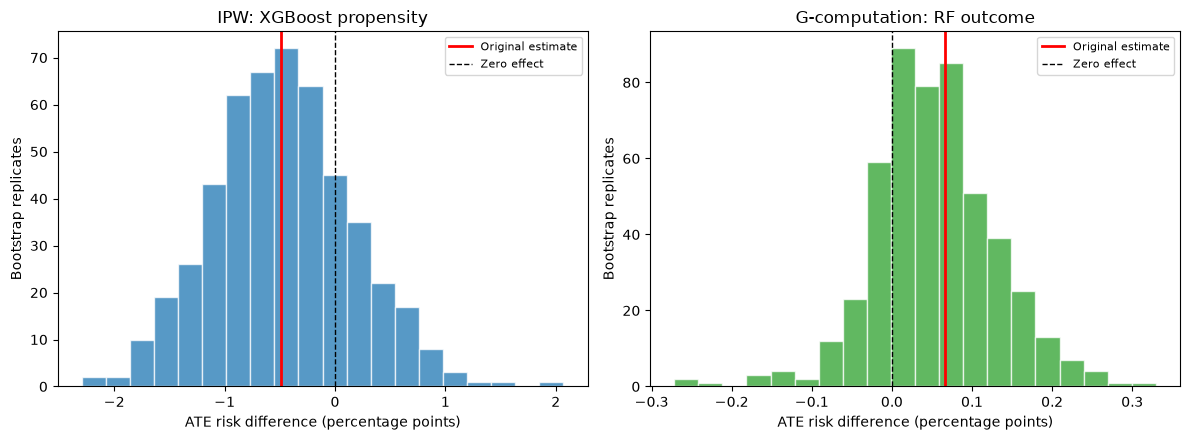

In [54]:
# ============================================================
# BOOTSTRAP DISTRIBUTIONS
# ============================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
)

plot_specs = [
    (
        "ipw_ate",
        primary_ipw_point,
        "IPW: XGBoost propensity",
        "tab:blue",
    ),
    (
        "gcomp_ate",
        primary_gcomp_point,
        "G-computation: RF outcome",
        "tab:green",
    ),
]

for ax, (
    column,
    point_estimate,
    title,
    color,
) in zip(axes, plot_specs):
    estimates_pp = (
        100 * bootstrap_results[column]
    )

    ax.hist(
        estimates_pp,
        bins=20,
        color=color,
        alpha=0.75,
        edgecolor="white",
    )

    ax.axvline(
        100 * point_estimate,
        color="red",
        linewidth=2,
        label="Original estimate",
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Zero effect",
    )

    ax.set_title(title)
    ax.set_xlabel(
        "ATE risk difference "
        "(percentage points)"
    )
    ax.set_ylabel(
        "Bootstrap replicates"
    )
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [55]:
# ============================================================
# UPDATE PRIMARY IPW AND G-COMPUTATION RESULTS
# ============================================================
ipw_mask = (
    (all_results["estimator"] == "IPW")
    & (
        all_results["propensity_model"]
        == PRIMARY_PS_MODEL
    )
)

gcomp_mask = (
    (
        all_results["estimator"]
        == "G-computation"
    )
    & (
        all_results["outcome_model"]
        == PRIMARY_OUTCOME_MODEL
    )
)

all_results.loc[
    ipw_mask,
    "standard_error",
] = ipw_bootstrap_summary[
    "bootstrap_standard_error"
]

all_results.loc[
    ipw_mask,
    "ci_lower",
] = ipw_bootstrap_summary["ci_lower"]

all_results.loc[
    ipw_mask,
    "ci_upper",
] = ipw_bootstrap_summary["ci_upper"]

all_results.loc[
    gcomp_mask,
    "standard_error",
] = gcomp_bootstrap_summary[
    "bootstrap_standard_error"
]

all_results.loc[
    gcomp_mask,
    "ci_lower",
] = gcomp_bootstrap_summary["ci_lower"]

all_results.loc[
    gcomp_mask,
    "ci_upper",
] = gcomp_bootstrap_summary["ci_upper"]

# Refresh display-scale columns.
all_results["risk_treated_pct"] = (
    100 * all_results["risk_treated"]
)

all_results["risk_control_pct"] = (
    100 * all_results["risk_control"]
)

all_results["ate_percentage_points"] = (
    100 * all_results["ate"]
)

all_results["ci_lower_pp"] = (
    100 * all_results["ci_lower"]
)

all_results["ci_upper_pp"] = (
    100 * all_results["ci_upper"]
)

primary_comparison = all_results.loc[
    ipw_mask
    | gcomp_mask
    | all_results["primary"],
    [
        "estimator",
        "propensity_model",
        "outcome_model",
        "risk_treated_pct",
        "risk_control_pct",
        "ate_percentage_points",
        "ci_lower_pp",
        "ci_upper_pp",
        "p_value",
        "primary",
    ],
]

display(
    primary_comparison.round(4)
)

,estimator,propensity_model,outcome_model,risk_treated_pct,risk_control_pct,ate_percentage_points,ci_lower_pp,ci_upper_pp,p_value,primary
2,IPW,xgb,None,5.7568,6.2478,-0.4910,-1.6570,0.7955,NaN,False
4,G-computation,None,rf,6.1815,6.1152,0.0663,-0.0899,0.2106,NaN,False
13,AIPW,xgb,rf,5.8372,6.2060,-0.3688,-1.5635,0.8258,0.5451,True


In [56]:
# ============================================================
# EXPORT BOOTSTRAP RESULTS
# ============================================================
bootstrap_results_path = (
    OUTPUT_DIR
    / "primary_ipw_gcomp_bootstrap_replicates.csv"
)

bootstrap_summary_path = (
    OUTPUT_DIR
    / "primary_ipw_gcomp_bootstrap_summary.csv"
)

updated_comparison_path = (
    OUTPUT_DIR
    / "ate_model_comparison_with_bootstrap.csv"
)

bootstrap_results.to_csv(
    bootstrap_results_path,
    index=False,
)

bootstrap_summary.to_csv(
    bootstrap_summary_path,
    index=False,
)

all_results.to_csv(
    updated_comparison_path,
    index=False,
)

print(
    "Saved bootstrap replicates to: "
    f"{bootstrap_results_path}"
)

print(
    "Saved bootstrap summary to: "
    f"{bootstrap_summary_path}"
)

print(
    "Saved updated estimator comparison to: "
    f"{updated_comparison_path}"
)

Saved bootstrap replicates to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/primary_ipw_gcomp_bootstrap_replicates.csv
Saved bootstrap summary to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/primary_ipw_gcomp_bootstrap_summary.csv
Saved updated estimator comparison to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs/ate_model_comparison_with_bootstrap.csv
